# Mini-Project 2: Uganda Tax Engine

**Student:** Tumuhirwe Iden · **Student number:** S26M25/011 · MSCS & MSDS OOP with Python, Assignment 2 (Advent 2026)

This notebook shows an extensible and testable tax calculator for taxes that the Uganda Revenue Authority (URA) administers. The code is in the package `src/uganda_tax/`. This notebook imports it.

## Rates used and their sources

The rates were checked on **5 October 2026**. The resident PAYE scale in the brief is the scale of the **Income Tax (Amendment) Act 2026**, in force from **1 July 2026** (FY 2026/27).

| Tax | Rule in the engine | Source (version) |
|---|---|---|
| PAYE, resident, monthly | Nil to 335,000; 20% to 410,000; 15,000 + 25% to 485,000; 33,750 + 30% above 485,000; plus 10% of the excess over 10,000,000 | [ura.go](https://ura.go.ug/en/domestic-taxes/paye-rates/) PAYE rates page; [pulse](https://www.pulse.ug/story/uganda-new-paye-rates-2026-guide-2026091410372290209) (in force from 1 July 2026) |
| PAYE, resident, before 1 July 2026 | Nil to 235,000; 10% to 335,000; 20% to 410,000; 30% above; plus 10% above 10,000,000 | Income Tax (Amendment) Act 2012; [calculator.sunpro](https://calculator.sunpro.africa/uganda-income-taxation) |
| PAYE, non-resident, monthly | 10% to 335,000; 33,500 + 20% to 410,000; 48,500 + 30% above; plus 10% above 10,000,000 | [ura.go](https://ura.go.ug/en/domestic-taxes/paye-rates/) |
| NSSF | Employee 5%, employer 10% of gross pay | [calculator.sunpro](https://calculator.sunpro.africa/uganda-income-taxation) (NSSF Act Cap. 230) |
| Local Service Tax | UGX 0 to 100,000 a year by monthly income band; 4 instalments, July to October; deducted before PAYE | [afrotools](https://afrotools.com/uganda/ug-paye); Local Governments (Amendment) Act 2008 |
| VAT | Standard 18%; zero-rated 0%; exempt: no VAT | [leadafrik](https://leadafrik.com/tax-rates-uganda) (VAT Act Cap. 349) |
| Corporate income tax | 30% for resident companies | [leadafrik](https://leadafrik.com/tax-rates-uganda); [taxatlas](https://taxatlas.io/country/uganda) |
| Withholding tax (extension) | 6% on supplies over 1,000,000 and on professional fees; 15% on dividends (10% listed), interest, and fees to non-residents | [URA Withholding Tax page](https://ura.go.ug/en/witholding-tax/) |
| Rental income tax (extension) | Individual: 12% of rent above 2,820,000 a year. Company: 30%, with expenses capped at 50% of rent | Income Tax (Amendment) Act 2022 |

All rates are in one module, `src/uganda_tax/rates.py`. When a Finance Act changes a rate, only that file changes.

In [1]:
import sys
from datetime import date
from decimal import Decimal
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

sys.path.insert(0, str(Path.cwd() / "src"))

from uganda_tax import (
    BusinessIncome, CorporateIncomeTax, EmploymentIncome, InvalidAmountError, InvalidIncomeError,
    Invoice, InvoiceDirection, LocalServiceTax, MissingContextDataError, Money, NoScheduleForDateError,
    NoWithholdingRuleError, OwnerType, Payment, PaymentCategory, PayeTax, Payroll, RentalIncome,
    RentalIncomeTax, Residency, SupplyType, Tax, TaxContext, TaxError, TaxResult, VatTax, WithholdingTax,
)

rng = np.random.default_rng(seed=2026)   # fixed seed: the sample salaries are the same on every run
TODAY = date(2026, 10, 5)                # a fixed date makes the results reproducible

## 1. Design overview

```
                         ┌──────────────────────────┐
                         │ Tax (ABC)                │
                         │ + calculate(ctx) ->      │
                         │       TaxResult          │
                         └────────────┬─────────────┘
     ┌──────────┬───────────┬─────────┼────────┬─────────────┬──────────────┐
  PayeTax   NssfContribution  LocalServiceTax  VatTax  CorporateIncomeTax  WithholdingTax, RentalIncomeTax
     │ has many                                                              (extension A)
  ProgressiveSchedule ── has ──► Band, EffectivePeriod

  Payroll ── has ──► PayeTax, NssfContribution ×2, LocalServiceTax  ──run(ctx)──► Payslip
  TaxContext ── has ──► EmploymentIncome | Invoice[] | BusinessIncome | RentalIncome | Payment
  Money: Decimal value object (UGX). TaxError ◄─ InvalidIncomeError, NoScheduleForDateError, ...
```

- **Abstraction.** `Tax` is an abstract base class with one method: `calculate(self, ctx: TaxContext) -> TaxResult`. Code that uses a tax does not need to know which tax it is.
- **Money.** `Money` holds a `Decimal` in UGX and never a `float`. It rounds to a whole shilling with `ROUND_HALF_UP` when it is created. It has `__add__`, `__sub__`, `__mul__`, `__truediv__`, `__lt__` (with `total_ordering`), `__eq__`, `__hash__`, `__repr__` and `__str__`.
- **Errors.** `TaxError` is the base. `InvalidIncomeError`, `NoScheduleForDateError`, `InvalidAmountError`, `MissingContextDataError` and `NoWithholdingRuleError` are subclasses. The engine never returns a guessed value. It raises an error or adds a note to the result.
- **Rates are data.** The rates go into the constructor. So a test or a new law can use other rates without changes to a class.

## 2. The `Money` value object

In [2]:
print(repr(Money(15_000)), "|", Money(1_234_567))
print("Rounding half up:", Money("2.5"), Money("2.4"), Money("-2.5"))
print("Operators:", Money(100_000) + Money(50_000), Money(1_000_000) * Decimal("0.18"),
      Money(100_000) / 4, Money(1) < Money(2))
try:
    Money(0.1)
except InvalidAmountError as error:
    print("float is refused:", error)

Money('15000') | UGX 1,234,567
Rounding half up: UGX 3 UGX 2 UGX -3
Operators: UGX 150,000 UGX 180,000 UGX 25,000 True
float is refused: Use Decimal, int or str for amounts, not float.


## 3. PAYE calculator

`PayeTax` selects the schedule by **residency** and **date**. The chargeable income is gross pay plus allowances, minus the deductions before PAYE (LST).

In [3]:
paye = PayeTax()

def paye_for(gross: int, residency: Residency = Residency.RESIDENT, on: date = TODAY,
             allowances: int = 0) -> TaxResult:
    ctx = TaxContext(on_date=on, residency=residency,
                     employment=EmploymentIncome(Money(gross), Money(allowances)))
    return paye.calculate(ctx)

result = paye_for(12_000_000)
print(result)
for line in result.lines:
    print(f"  {line.label:<34} base {str(line.base):>16}  tax {str(line.amount):>14}")
print(*result.notes, sep="\n")

PAYE: UGX 3,688,250 on UGX 12,000,000
  0% over 0 to 335,000               base      UGX 335,000  tax          UGX 0
  20% over 335,000 to 410,000        base       UGX 75,000  tax     UGX 15,000
  25% over 410,000 to 485,000        base       UGX 75,000  tax     UGX 18,750
  30% over 485,000                   base   UGX 11,515,000  tax  UGX 3,454,500
  10% over 10,000,000                base    UGX 2,000,000  tax    UGX 200,000
Schedule: Resident monthly PAYE, FY 2026/27 onwards (2026-07-01 to today).
Source: URA PAYE rates page (https://ura.go.ug/en/domestic-taxes/paye-rates/), checked 2026-10-05.


### Boundary values at every band edge

In [4]:
edges = [335_000, 335_001, 410_000, 485_000, 10_000_000, 10_000_001]
pd.DataFrame(
    {
        "Resident PAYE (UGX)": [paye_for(g).amount.amount for g in edges],
        "Non-resident PAYE (UGX)": [paye_for(g, Residency.NON_RESIDENT).amount.amount for g in edges],
        "Resident, before 1 July 2026 (UGX)": [paye_for(g, on=date(2026, 6, 30)).amount.amount for g in edges],
    },
    index=pd.Index([f"{g:,}" for g in edges], name="Monthly chargeable income (UGX)"),
)

,Resident PAYE (UGX),Non-resident PAYE (UGX),"Resident, before 1 July 2026 (UGX)"
Monthly chargeable income (UGX),,,
"335,000",0,33500,10000
"335,001",0,33500,10000
"410,000",15000,48500,25000
"485,000",33750,71000,47500
"10,000,000",2888250,2925500,2902000
"10,000,001",2888250,2925500,2902000


At 335,001 the extra tax is 20% of UGX 1 = 0.2, which rounds to 0. At 10,000,001 the extra tax is 30% + 10% of UGX 1 = 0.4, which also rounds to 0. The boundary tests in `tests/test_paye.py` check every edge, and also values such as 10,000,010, where the 10% surcharge starts to show.

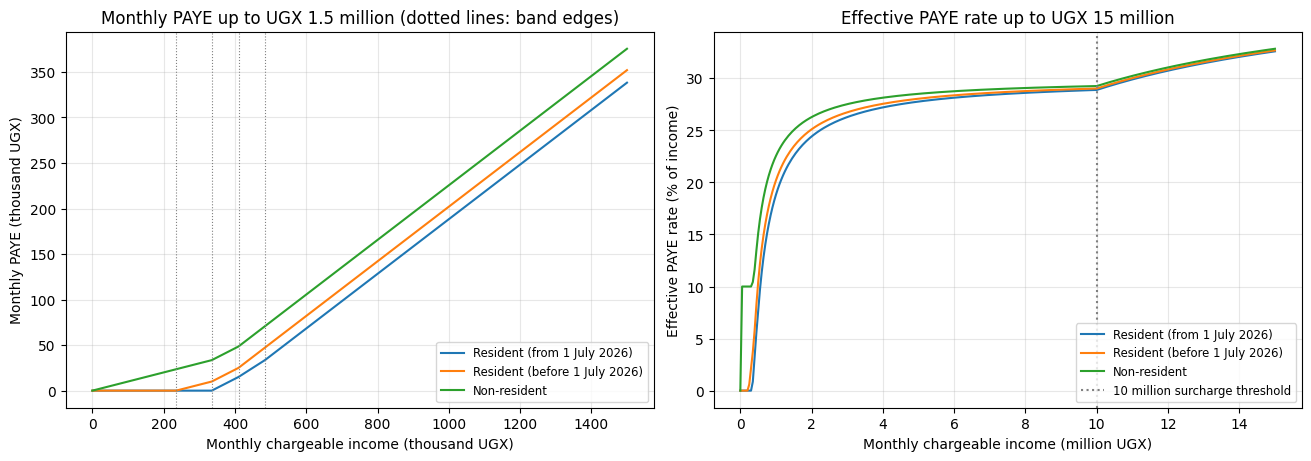

In [5]:
low_incomes = np.arange(0, 1_500_001, 5_000)       # left panel: where the scales differ
all_incomes = np.arange(0, 15_000_001, 50_000)     # right panel: up to 15 million
fig, (ax_tax, ax_rate) = plt.subplots(1, 2, figsize=(13, 4.5), layout="constrained")
series = {
    "Resident (from 1 July 2026)": dict(residency=Residency.RESIDENT, on=TODAY),
    "Resident (before 1 July 2026)": dict(residency=Residency.RESIDENT, on=date(2026, 6, 30)),
    "Non-resident": dict(residency=Residency.NON_RESIDENT, on=TODAY),
}

def paye_values(incomes: np.ndarray, options: dict) -> np.ndarray:
    # float is used only to draw the chart, never to calculate tax
    return np.array([float(paye_for(int(g), **options).amount.amount) for g in incomes])

for label, options in series.items():
    ax_tax.plot(low_incomes / 1e3, paye_values(low_incomes, options) / 1e3, label=label)
    taxes = paye_values(all_incomes, options)
    rates = np.divide(taxes, all_incomes, out=np.zeros_like(taxes), where=all_incomes > 0) * 100
    ax_rate.plot(all_incomes / 1e6, rates, label=label)
for edge in (235, 335, 410, 485):
    ax_tax.axvline(edge, color="grey", linestyle=":", linewidth=0.8)
ax_rate.axvline(10, color="grey", linestyle=":", label="10 million surcharge threshold")
ax_tax.set_xlabel("Monthly chargeable income (thousand UGX)")
ax_tax.set_ylabel("Monthly PAYE (thousand UGX)")
ax_tax.set_title("Monthly PAYE up to UGX 1.5 million (dotted lines: band edges)")
ax_rate.set_xlabel("Monthly chargeable income (million UGX)")
ax_rate.set_ylabel("Effective PAYE rate (% of income)")
ax_rate.set_title("Effective PAYE rate up to UGX 15 million")
for ax in (ax_tax, ax_rate):
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize="small")
plt.show()

The 2026 scale gives less tax than the old scale to every resident who earns more than UGX 235,000. The nil band is now 335,000, not 235,000, and the 410,000 to 485,000 band is now 25%, not 30%. The effective rate goes up slowly towards 40%, but it never reaches 40%.

## 4. Payroll pipeline

### Order of deductions and why

1. **Total gross** = gross pay + allowances. Cash allowances are employment income, so they are taxable.
2. **Local Service Tax** (if turned on). LST is an allowable deduction for PAYE ([afrotools], [calculator.sunpro]). So we must know it **before** PAYE. It is paid in 4 instalments from July to October. In other months it is 0.
3. **PAYE** on total gross minus LST.
4. **NSSF**: 5% from the employee and 10% from the employer, on total gross. Employee NSSF does **not** reduce the PAYE base ([afrotools]). So its place after PAYE does not change PAYE. We put it after PAYE to show this.
5. **Net pay** = total gross − LST − PAYE − employee NSSF. The employer share is not taken from the employee. It is a cost to the employer.

If NSSF came before PAYE and reduced the base, PAYE would be too low. If LST came after PAYE, PAYE would be too high in the LST months.

In [6]:
payroll = Payroll(lst=LocalServiceTax())   # LST turned on; Payroll() turns it off
august = TaxContext(on_date=date(2026, 8, 31),
                    employment=EmploymentIncome(gross_pay=Money(2_000_000), allowances=Money(500_000)))
print(payroll.run(august))

Total gross pay              UGX 2,500,000
Local Service Tax               UGX 25,000
PAYE chargeable income       UGX 2,475,000
PAYE                           UGX 630,750
NSSF employee (5%)             UGX 125,000
Net pay                      UGX 1,719,250
NSSF employer (10%)            UGX 250,000
Total employer cost          UGX 2,750,000


In [7]:
salaries = np.sort(rng.integers(300, 6_000, size=8)) * 1_000   # random monthly salaries, fixed seed
slips = [payroll.run(TaxContext(on_date=date(2026, 8, 31),
                                employment=EmploymentIncome(Money(int(s))))) for s in salaries]
payroll_table = pd.DataFrame(
    [{label: amount.amount for label, amount in slip.as_rows()} for slip in slips]
).astype("int64")
payroll_table

,Total gross pay,Local Service Tax,PAYE chargeable income,PAYE,NSSF employee (5%),Net pay,NSSF employer (10%),Total employer cost
0,450000,7500,442500,23125,22500,396875,45000,495000
1,755000,17500,737500,109500,37750,590250,75500,830500
2,1319000,25000,1294000,276450,65950,951600,131900,1450900
3,2383000,25000,2358000,595650,119150,1643200,238300,2621300
4,2411000,25000,2386000,604050,120550,1661400,241100,2652100
5,2963000,25000,2938000,769650,148150,2020200,296300,3259300
6,3947000,25000,3922000,1064850,197350,2659800,394700,4341700
7,5155000,25000,5130000,1427250,257750,3445000,515500,5670500


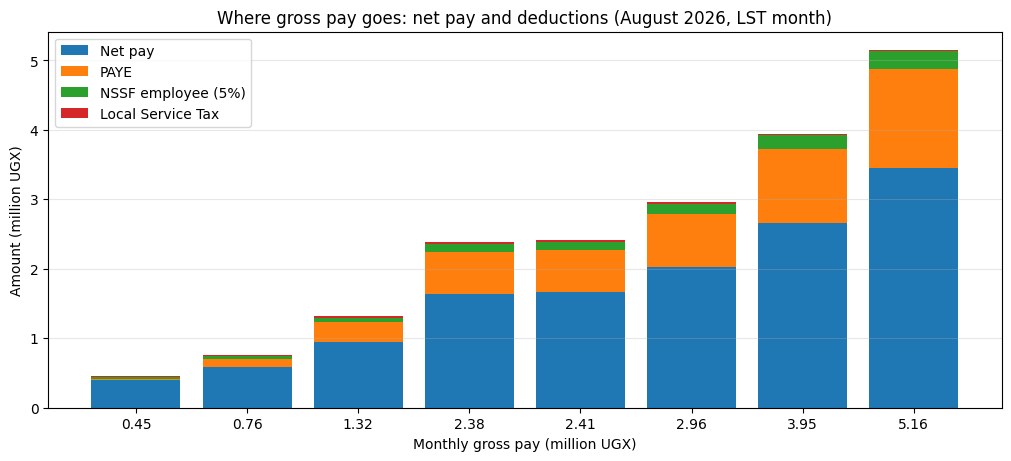

In [8]:
parts = ["Net pay", "PAYE", "NSSF employee (5%)", "Local Service Tax"]
labels = [f"{s / 1e6:.2f}" for s in salaries]
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
bottom = np.zeros(len(salaries))
for column in parts:
    values = payroll_table[column].to_numpy() / 1e6
    ax.bar(labels, values, bottom=bottom, label=column)
    bottom += values
ax.set_xlabel("Monthly gross pay (million UGX)")
ax.set_ylabel("Amount (million UGX)")
ax.set_title("Where gross pay goes: net pay and deductions (August 2026, LST month)")
ax.legend()
ax.grid(True, axis="y", alpha=0.3)
plt.show()

## 5. VAT module

Each invoice has a direction (sale or purchase), a supply type and a net amount (without VAT). Output VAT is the VAT on sales. Input VAT is the VAT on purchases. Exempt supplies have no VAT and give no input VAT credit. Zero-rated supplies are taxable at 0%.

In [9]:
invoices = (
    Invoice("S-001", InvoiceDirection.SALE, SupplyType.STANDARD, Money(25_000_000)),
    Invoice("S-002", InvoiceDirection.SALE, SupplyType.ZERO_RATED, Money(8_000_000)),   # e.g. an export
    Invoice("S-003", InvoiceDirection.SALE, SupplyType.EXEMPT, Money(3_000_000)),       # e.g. an exempt service
    Invoice("P-101", InvoiceDirection.PURCHASE, SupplyType.STANDARD, Money(12_000_000)),
    Invoice("P-102", InvoiceDirection.PURCHASE, SupplyType.EXEMPT, Money(1_500_000)),
)
vat = VatTax()
vat_result = vat.calculate(TaxContext(on_date=TODAY, invoices=invoices))
display(pd.DataFrame([{"Invoice": l.label, "Net amount (UGX)": l.base.amount, "Rate": f"{l.rate:.0%}",
                       "VAT (UGX, + output / − input)": l.amount.amount} for l in vat_result.lines]))
print("Output VAT:", vat.output_vat(TaxContext(on_date=TODAY, invoices=invoices)))
print("Input VAT: ", vat.input_vat(TaxContext(on_date=TODAY, invoices=invoices)))
print("Net VAT payable:", vat_result.amount)

,Invoice,Net amount (UGX),Rate,"VAT (UGX, + output / − input)"
0,"S-001: sale, standard",25000000,18%,4500000
1,"S-002: sale, zero_rated",8000000,0%,0
2,"S-003: sale, exempt",3000000,0%,0
3,"P-101: purchase, standard",12000000,18%,-2160000
4,"P-102: purchase, exempt",1500000,0%,0


Output VAT: UGX 4,500,000
Input VAT:  UGX 2,160,000
Net VAT payable: UGX 2,340,000


## 6. Corporate income tax

In [10]:
cit = CorporateIncomeTax()
for revenue, deductions in [(900_000_000, 620_000_000), (150_000_000, 180_000_000)]:
    ctx = TaxContext(on_date=TODAY, business=BusinessIncome(Money(revenue), Money(deductions)))
    r = cit.calculate(ctx)
    print(f"Revenue {Money(revenue)}, deductions {Money(deductions)} -> chargeable {r.taxable_base}, "
          f"tax {r.amount}", *r.notes)

Revenue UGX 900,000,000, deductions UGX 620,000,000 -> chargeable UGX 280,000,000, tax UGX 84,000,000
Revenue UGX 150,000,000, deductions UGX 180,000,000 -> chargeable UGX 0, tax UGX 0 Tax loss of UGX 30,000,000 to carry forward.


## 7. Validation and errors

The engine never fails silently. Each bad input gives a clear error from the `TaxError` hierarchy.

In [11]:
bad_inputs = {
    "Negative gross pay": lambda: EmploymentIncome(Money(-50_000)),
    "Date before any PAYE schedule": lambda: paye_for(500_000, on=date(2010, 1, 1)),
    "PAYE with no employment data": lambda: PayeTax().calculate(TaxContext(on_date=TODAY)),
    "Money from a float": lambda: Money(0.18),
    "Withholding on goods from a non-resident": lambda: WithholdingTax().calculate(TaxContext(
        on_date=TODAY, payment=Payment(PaymentCategory.SUPPLIES, Money(5_000_000), Residency.NON_RESIDENT))),
}
for label, action in bad_inputs.items():
    try:
        action()
    except TaxError as error:
        print(f"{label:<42} -> {type(error).__name__}: {error}")

Negative gross pay                         -> InvalidIncomeError: Gross pay must not be negative, but it is UGX -50,000.
Date before any PAYE schedule              -> NoScheduleForDateError: No resident PAYE schedule applies on 2010-01-01.
PAYE with no employment data               -> MissingContextDataError: This tax needs employment income in the context.
Money from a float                         -> InvalidAmountError: Use Decimal, int or str for amounts, not float.
Withholding on goods from a non-resident   -> NoWithholdingRuleError: No withholding rule for supplies of goods or services paid to a non_resident payee.


## 8. Extension task A: withholding tax and rental income tax

We chose **extension A**, because both taxes fit the same `Tax` interface. No change to the existing classes was necessary. This shows that the design is open for extension.

- **`WithholdingTax`** uses a rate table keyed by `(payment category, payee residency)`. Supplies of goods and services have a UGX 1,000,000 threshold. A resident shareholder of a listed company gets the 10% dividend rate. When the table has no rule, the class raises `NoWithholdingRuleError`. It does not use 0% as a silent default.
- **`RentalIncomeTax`** has two rules. An individual pays 12% of gross rent above UGX 2,820,000 a year, and cannot deduct expenses. A company pays 30% of rent minus expenses, but deductible expenses are capped at 50% of the rent. So the effective rate for a company is at most 15% of gross rent, and at least 0%. The rules started on 1 July 2022, so an earlier date raises `NoScheduleForDateError`.

In [12]:
wht = WithholdingTax()
payments = [
    Payment(PaymentCategory.SUPPLIES, Money(800_000)),
    Payment(PaymentCategory.SUPPLIES, Money(4_000_000)),
    Payment(PaymentCategory.PROFESSIONAL_FEES, Money(3_000_000), Residency.NON_RESIDENT),
    Payment(PaymentCategory.DIVIDENDS, Money(10_000_000), listed_company_dividend=True),
    Payment(PaymentCategory.INTEREST, Money(2_000_000)),
]
pd.DataFrame([{
    "Payment": p.category.value, "Payee": p.payee_residency.value,
    "Gross (UGX)": p.gross_amount.amount,
    "Withheld (UGX)": (r := wht.calculate(TaxContext(on_date=TODAY, payment=p))).amount.amount,
    "Note": r.notes[0],
} for p in payments])

,Payment,Payee,Gross (UGX),Withheld (UGX),Note
0,supplies of goods or services,resident,800000,0,"Payment is not more than UGX 1,000,000, so no ..."
1,supplies of goods or services,resident,4000000,240000,"Net amount paid to the payee: UGX 3,760,000."
2,management or professional fees,non_resident,3000000,450000,"Net amount paid to the payee: UGX 2,550,000."
3,dividends,resident,10000000,1000000,"Net amount paid to the payee: UGX 9,000,000."
4,interest,resident,2000000,300000,"Net amount paid to the payee: UGX 1,700,000."


In [13]:
rental = RentalIncomeTax()
cases = [(OwnerType.INDIVIDUAL, 2_500_000, 0), (OwnerType.INDIVIDUAL, 24_000_000, 6_000_000),
         (OwnerType.COMPANY, 60_000_000, 12_000_000), (OwnerType.COMPANY, 60_000_000, 45_000_000)]
pd.DataFrame([{
    "Owner": owner.value, "Gross rent (UGX)": rent, "Expenses (UGX)": expenses,
    "Chargeable (UGX)": (r := rental.calculate(TaxContext(on_date=TODAY, rental=RentalIncome(
        owner, Money(rent), Money(expenses))))).taxable_base.amount,
    "Tax (UGX)": r.amount.amount, "Note": "; ".join(r.notes),
} for owner, rent, expenses in cases])

,Owner,Gross rent (UGX),Expenses (UGX),Chargeable (UGX),Tax (UGX),Note
0,individual,2500000,0,0,0,
1,individual,24000000,6000000,21180000,2541600,Expenses are not deductible for an individual.
2,company,60000000,12000000,48000000,14400000,
3,company,60000000,45000000,30000000,9000000,"Expenses capped at 50% of rent: UGX 30,000,000."


## 9. Tests

The tests are in `tests/` and run with `pytest`:

- `test_paye.py`: boundary tests at every band edge (335,000; 335,001; 410,000; 485,000; 10,000,000; 10,000,001) for resident and non-resident scales, the change of scale on 1 July 2026, and the date errors.
- `test_properties.py`: **Hypothesis** property tests. For any income, any residency and any date, PAYE is non-negative, monotonic in income, and never more than income. Net pay is between 0 and gross pay. Corporate and rental tax also have these properties. Hypothesis uses a fixed seed (`derandomize=True`).
- `test_money.py` and `test_modules.py`: rounding, operators, payroll order, VAT, corporate tax and the extension modules.

The next cell runs the test suite from the notebook.

In [14]:
import subprocess
completed = subprocess.run([sys.executable, "-m", "pytest", "-q", "--color=no", "tests"], capture_output=True, text=True)
print(completed.stdout[-600:])
assert completed.returncode == 0, completed.stderr

........................................................................ [ 96%]
...                                                                      [100%]
75 passed in 0.97s



## 10. Discussion questions

### 10.1 Why is `float` unsafe for tax computation?

A `float` stores a number in binary. Most decimal fractions, such as 0.1 or 4.35, have no exact binary value. So small errors come into each step. In tax work, these errors change totals, comparisons with thresholds, and rounding. The next cell shows concrete failures and the correct `Decimal` results.

In [15]:
examples = pd.DataFrame([
    ("Add 0.1 + 0.2", 0.1 + 0.2 == 0.3, Decimal("0.1") + Decimal("0.2") == Decimal("0.3")),
    ("3 payments of 410,000.10 equal 1,230,000.30",
     sum([410_000.10] * 3) == 1_230_000.30, sum([Decimal("410000.10")] * 3) == Decimal("1230000.30")),
    ("int(4.35 * 100) is 435 (rate in % to basis points)",
     int(4.35 * 100) == 435, int(Decimal("4.35") * 100) == 435),
    ("Round UGX 2.5 half up to 3", round(2.5) == 3, Money("2.5") == Money(3)),
], columns=["Check", "float gives correct answer", "Decimal / Money gives correct answer"])
display(examples)
print("float values:", 0.1 + 0.2, sum([410_000.10] * 3), 4.35 * 100, round(2.5))

,Check,float gives correct answer,Decimal / Money gives correct answer
0,Add 0.1 + 0.2,False,True
1,"3 payments of 410,000.10 equal 1,230,000.30",False,True
2,int(4.35 * 100) is 435 (rate in % to basis poi...,False,True
3,Round UGX 2.5 half up to 3,False,True


float values: 0.30000000000000004 1230000.2999999998 434.99999999999994 2


- `sum([410_000.10] * 3)` gives `1230000.2999999998`. A check such as `total == 1_230_000.30` fails, and an audit finds a difference.
- `4.35 * 100` gives `434.99999999999994`, so `int()` gives 434, not 435. A rate or an amount changed with `int()` loses one unit.
- Python's `round()` uses "round half to even", so `round(2.5)` is 2. The engine needs an explicit, documented rule (half up), and `Decimal.quantize` gives that rule.
- A value that is a little below a band edge (for example 334,999.99999 instead of 335,000) can go into the wrong band.

`Decimal` stores decimal digits exactly, and the rounding mode is explicit. So the `Money` class accepts only `Decimal`, `int` or `str`, and refuses `float`.

### 10.2 Where is inheritance justified, and where did we avoid it?

**Inheritance is used where there is a true "is-a" relation and a shared interface.** Each tax (`PayeTax`, `VatTax`, `CorporateIncomeTax`, `LocalServiceTax`, `NssfContribution`, `WithholdingTax`, `RentalIncomeTax`) **is a** `Tax`. The abstract base class makes every tax give the same `calculate(ctx) -> TaxResult` method. So the payroll, a report, or a future planner can use any tax in the same way. This is also how we added extension A with no change to old code. The exception hierarchy also uses inheritance. A caller can catch all engine errors with `except TaxError`, or catch one type, such as `NoScheduleForDateError`. Some errors also inherit from a built-in type (`ValueError`, `LookupError`), so general code can handle them too.

**We avoided inheritance in these places:**
- **Resident and non-resident PAYE are not subclasses.** They have the same algorithm and different numbers. So they are two `ProgressiveSchedule` **data objects**, and one `PayeTax` selects the schedule by residency and date. Subclasses would copy the band logic, and each new Finance Act would need a new class.
- **The NSSF employee and employer shares are not subclasses.** They are two instances of one class with different rates (`NssfContribution.employee()` and `.employer()`).
- **`Payroll` is not a subclass of `Tax`.** A payroll is not a tax. It **has** a PAYE calculator, two NSSF contributions and an LST calculator (composition). It returns a `Payslip`, not one `TaxResult`.
- **`TaxContext` uses composition.** It holds optional records (`EmploymentIncome`, `Invoice`s, `BusinessIncome`, ...). It is not a tree of context subclasses. So the abstract method keeps the exact signature `calculate(self, ctx: TaxContext)`, and each tax asks only for the record that it needs.
- **`Money` is not a subclass of `Decimal`.** If it were, all `Decimal` operations would be available, for example `Money * Money` or a mix with plain numbers, and these have no meaning for money. Composition (a `Money` *has* a `Decimal`) lets us allow only the safe operators.

**Summary:** we use inheritance for a shared interface (`Tax`, `TaxError`). We use composition and data objects for the variation in rates and for objects that combine other objects.